# **New York City Yellow Taxi Data**

## Objective
In this case study you will be learning exploratory data analysis (EDA) with the help of a dataset on yellow taxi rides in New York City. This will enable you to understand why EDA is an important step in the process of data science and machine learning.

## **Problem Statement**
As an analyst at an upcoming taxi operation in NYC, you are tasked to use the 2023 taxi trip data to uncover insights that could help optimise taxi operations. The goal is to analyse patterns in the data that can inform strategic decisions to improve service efficiency, maximise revenue, and enhance passenger experience.

## Tasks
You need to perform the following steps for successfully completing this assignment:
1. Data Loading
2. Data Cleaning
3. Exploratory Analysis: Bivariate and Multivariate
4. Creating Visualisations to Support the Analysis
5. Deriving Insights and Stating Conclusions

---

**NOTE:** The marks given along with headings and sub-headings are cumulative marks for those particular headings/sub-headings.<br>

The actual marks for each task are specified within the tasks themselves.

For example, marks given with heading *2* or sub-heading *2.1* are the cumulative marks, for your reference only. <br>

The marks you will receive for completing tasks are given with the tasks.

Suppose the marks for two tasks are: 3 marks for 2.1.1 and 2 marks for 3.2.2, or
* 2.1.1 [3 marks]
* 3.2.2 [2 marks]

then, you will earn 3 marks for completing task 2.1.1 and 2 marks for completing task 3.2.2.


---

## Data Understanding
The yellow taxi trip records include fields capturing pick-up and drop-off dates/times, pick-up and drop-off locations, trip distances, itemized fares, rate types, payment types, and driver-reported passenger counts.

The data is stored in Parquet format (*.parquet*). The dataset is from 2009 to 2024. However, for this assignment, we will only be using the data from 2023.

The data for each month is present in a different parquet file. You will get twelve files for each of the months in 2023.

The data was collected and provided to the NYC Taxi and Limousine Commission (TLC) by technology providers like vendors and taxi hailing apps. <br>

You can find the link to the TLC trip records page here: https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page

###  Data Description
You can find the data description here: [Data Dictionary](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf)

**Trip Records**



|Field Name       |description |
|:----------------|:-----------|
| VendorID | A code indicating the TPEP provider that provided the record. <br> 1= Creative Mobile Technologies, LLC; <br> 2= VeriFone Inc. |
| tpep_pickup_datetime | The date and time when the meter was engaged.  |
| tpep_dropoff_datetime | The date and time when the meter was disengaged.   |
| Passenger_count | The number of passengers in the vehicle. <br> This is a driver-entered value. |
| Trip_distance | The elapsed trip distance in miles reported by the taximeter. |
| PULocationID | TLC Taxi Zone in which the taximeter was engaged |
| DOLocationID | TLC Taxi Zone in which the taximeter was disengaged |
|RateCodeID |The final rate code in effect at the end of the trip.<br> 1 = Standard rate <br> 2 = JFK <br> 3 = Newark <br>4 = Nassau or Westchester <br>5 = Negotiated fare <br>6 = Group ride |
|Store_and_fwd_flag |This flag indicates whether the trip record was held in vehicle memory before sending to the vendor, aka “store and forward,” because the vehicle did not have a connection to the server.  <br>Y= store and forward trip <br>N= not a store and forward trip |
|Payment_type| A numeric code signifying how the passenger paid for the trip. <br> 1 = Credit card <br>2 = Cash <br>3 = No charge <br>4 = Dispute <br>5 = Unknown <br>6 = Voided trip |
|Fare_amount| The time-and-distance fare calculated by the meter. <br>Extra Miscellaneous extras and surcharges.  Currently, this only includes the 0.50 and 1 USD rush hour and overnight charges. |
|MTA_tax |0.50 USD MTA tax that is automatically triggered based on the metered rate in use. |
|Improvement_surcharge | 0.30 USD improvement surcharge assessed trips at the flag drop. The improvement surcharge began being levied in 2015. |
|Tip_amount |Tip amount – This field is automatically populated for credit card tips. Cash tips are not included. |
| Tolls_amount | Total amount of all tolls paid in trip.  |
| total_amount | The total amount charged to passengers. Does not include cash tips. |
|Congestion_Surcharge |Total amount collected in trip for NYS congestion surcharge. |
| Airport_fee | 1.25 USD for pick up only at LaGuardia and John F. Kennedy Airports|

Although the amounts of extra charges and taxes applied are specified in the data dictionary, you will see that some cases have different values of these charges in the actual data.

**Taxi Zones**

Each of the trip records contains a field corresponding to the location of the pickup or drop-off of the trip, populated by numbers ranging from 1-263.

These numbers correspond to taxi zones, which may be downloaded as a table or map/shapefile and matched to the trip records using a join.

This is covered in more detail in later sections.

---

## **1** Data Preparation

<font color = red>[5 marks]</font> <br>

### Import Libraries

In [56]:
import warnings
warnings.filterwarnings('ignore')

In [57]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [58]:
# Import the libraries you will be using for analysis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [59]:
# Recommended versions
# numpy version: 1.26.4
# pandas version: 2.2.2
# matplotlib version: 3.10.0
# seaborn version: 0.13.2

# Check versions
print("numpy version:", np.__version__)
print("pandas version:", pd.__version__)
print("matplotlib version:", plt.matplotlib.__version__)
print("seaborn version:", sns.__version__)

numpy version: 2.1.3
pandas version: 2.2.3
matplotlib version: 3.10.0
seaborn version: 0.13.2


### **1.1** Load the dataset
<font color = red>[5 marks]</font> <br>

You will see twelve files, one for each month.

To read parquet files with Pandas, you have to follow a similar syntax as that for CSV files.

`df = pd.read_parquet('file.parquet')`

In [60]:
import os
import pandas as pd
import numpy as np

trip_path = '/content/drive/MyDrive/Datasets and Dictionary/trip_records'

files = [
    os.path.join(trip_path, f'2023-{month}.parquet')
    for month in range(1, 13)
]

files

['/content/drive/MyDrive/Datasets and Dictionary/trip_records/2023-1.parquet',
 '/content/drive/MyDrive/Datasets and Dictionary/trip_records/2023-2.parquet',
 '/content/drive/MyDrive/Datasets and Dictionary/trip_records/2023-3.parquet',
 '/content/drive/MyDrive/Datasets and Dictionary/trip_records/2023-4.parquet',
 '/content/drive/MyDrive/Datasets and Dictionary/trip_records/2023-5.parquet',
 '/content/drive/MyDrive/Datasets and Dictionary/trip_records/2023-6.parquet',
 '/content/drive/MyDrive/Datasets and Dictionary/trip_records/2023-7.parquet',
 '/content/drive/MyDrive/Datasets and Dictionary/trip_records/2023-8.parquet',
 '/content/drive/MyDrive/Datasets and Dictionary/trip_records/2023-9.parquet',
 '/content/drive/MyDrive/Datasets and Dictionary/trip_records/2023-10.parquet',
 '/content/drive/MyDrive/Datasets and Dictionary/trip_records/2023-11.parquet',
 '/content/drive/MyDrive/Datasets and Dictionary/trip_records/2023-12.parquet']

How many rows are there? Do you think handling such a large number of rows is computationally feasible when we have to combine the data for all twelve months into one?

To handle this, we need to sample a fraction of data from each of the files. How to go about that? Think of a way to select only some portion of the data from each month's file that accurately represents the trends.

#### Sampling the Data
> One way is to take a small percentage of entries for pickup in every hour of a date. So, for all the days in a month, we can iterate through the hours and select 5% values randomly from those. Use `tpep_pickup_datetime` for this. Separate date and hour from the datetime values and then for each date, select some fraction of trips for each of the 24 hours.

To sample data, you can use the `sample()` method. Follow this syntax:

```Python
# sampled_data is an empty DF to keep appending sampled data of each hour
# hour_data is the DF of entries for an hour 'X' on a date 'Y'

sample = hour_data.sample(frac = 0.05, random_state = 42)
# sample 0.05 of the hour_data
# random_state is just a seed for sampling, you can define it yourself

sampled_data = pd.concat([sampled_data, sample]) # adding data for this hour to the DF
```

This *sampled_data* will contain 5% values selected at random from each hour.

Note that the code given above is only the part that will be used for sampling and not the complete code required for sampling and combining the data files.

Keep in mind that you sample by date AND hour, not just hour. (Why?)

---

**1.1.1** <font color = red>[5 marks]</font> <br>
Figure out how to sample and combine the files.

**Note:** It is not mandatory to use the method specified above. While sampling, you only need to make sure that your sampled data represents the overall data of all the months accurately.

In [61]:
# Sample the data
# It is recommmended to not load all the files at once to avoid memory overload

In [62]:
import os

# Select the folder having data files
# The 'trip_path' variable is already defined globally and points to the correct directory.
# Instead of changing the current directory, we will directly use 'trip_path' to construct file paths.
# os.chdir('/content/drive/MyDrive/Datasets and Dictionary/trip_records') # Commented out to avoid FileNotFoundError

# Create a list of all the twelve files to read
# Use trip_path to list files in the correct directory
file_list = sorted(
    [file for file in os.listdir(trip_path) if file.endswith('.parquet')],
    key=lambda x: int(x.split('-')[1].split('.')[0])
)

# initialise an empty dataframe
df = pd.DataFrame()


# iterate through the list of files and sample one by one:
for file_name in file_list:
    try:
        # file path for the current file
        # Use trip_path directly instead of os.getcwd() after chdir
        file_path = os.path.join(trip_path, file_name)

        # Reading the current file
        month_data = pd.read_parquet(file_path)

        # Convert pickup datetime to datetime format
        month_data['tpep_pickup_datetime'] = pd.to_datetime(
            month_data['tpep_pickup_datetime']
        )

        # Create date and hour columns once
        month_data['pickup_date'] = month_data[
            'tpep_pickup_datetime'
        ].dt.date

        month_data['pickup_hour'] = month_data[
            'tpep_pickup_datetime'
        ].dt.hour

        # We will store the sampled data for the current date by appending
        # the sampled data from each hour to this
        sampled_data = pd.DataFrame()

        # Loop through dates and then loop through every hour of each date
        for date in month_data['pickup_date'].unique():

            # Select data for the current date only
            date_data = month_data[
                month_data['pickup_date'] == date
            ]

            # Iterate through each hour of the selected date
            for hour in range(24):

                hour_data = date_data[
                    date_data['pickup_hour'] == hour
                ]

                # Sample 5% of the hourly data randomly
                if len(hour_data) > 0:
                    sample = hour_data.sample(
                        frac=0.05,
                        random_state=42
                    )

                    # add data of this hour to the dataframe
                    sampled_data = pd.concat(
                        [sampled_data, sample],
                        ignore_index=True
                    )

        # Remove temporary columns
        sampled_data.drop(
            columns=['pickup_date', 'pickup_hour'],
            inplace=True
        )

        # Concatenate the sampled data of all the dates to a single dataframe
        df = pd.concat(
            [df, sampled_data],
            ignore_index=True
        )

        print(
            f"{file_name}: "
            f"{len(month_data):,} original rows -> "
            f"{len(sampled_data):,} sampled rows"
        )

        del month_data
        del sampled_data

    except Exception as e:
        print(f"Error reading file {file_name}: {e}")

print("\nFinal sampled dataset shape:", df.shape)

2023-1.parquet: 3,041,714 original rows -> 152,087 sampled rows
2023-2.parquet: 3,374,086 original rows -> 168,696 sampled rows
2023-3.parquet: 3,275,796 original rows -> 163,786 sampled rows
2023-4.parquet: 2,792,901 original rows -> 139,641 sampled rows
2023-5.parquet: 2,889,185 original rows -> 144,458 sampled rows
2023-6.parquet: 3,258,261 original rows -> 162,910 sampled rows
2023-7.parquet: 3,481,547 original rows -> 174,068 sampled rows
2023-8.parquet: 2,875,947 original rows -> 143,782 sampled rows
2023-9.parquet: 2,817,156 original rows -> 140,875 sampled rows
2023-10.parquet: 3,485,185 original rows -> 174,255 sampled rows
2023-11.parquet: 3,302,857 original rows -> 165,133 sampled rows
2023-12.parquet: 3,333,925 original rows -> 166,709 sampled rows

Final sampled dataset shape: (1896400, 20)


In [63]:
if os.path.exists(trip_path):
    print(f"The directory '{trip_path}' exists.")
else:
    print(f"The directory '{trip_path}' does NOT exist. Please ensure Google Drive is mounted and the path is correct.")

The directory '/content/drive/MyDrive/Datasets and Dictionary/trip_records' exists.


After combining the data files into one DataFrame, convert the new DataFrame to a CSV or parquet file and store it to use directly.

Ideally, you can try keeping the total entries to around 250,000 to 300,000.

In [64]:
# Store the df in csv/parquet
# df.to_parquet('')

# Store the df in parquet
sample_file = '/content/drive/MyDrive/Datasets and Dictionary/NYC_Taxi_2023_sample.parquet'

df.to_parquet(sample_file, index=False)

print("File saved successfully.")
print(sample_file)
print("Shape:", df.shape)

File saved successfully.
/content/drive/MyDrive/Datasets and Dictionary/NYC_Taxi_2023_sample.parquet
Shape: (1896400, 20)


## **2** Data Cleaning
<font color = red>[30 marks]</font> <br>

Now we can load the new data directly.

In [65]:
# Load the new data file

sample_file = '/content/drive/MyDrive/Datasets and Dictionary/NYC_Taxi_2023_sample.parquet'

df = pd.read_parquet(sample_file)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (1896400, 20)


#### **2.1** Fixing Columns
<font color = red>[10 marks]</font> <br>

Fix/drop any columns as you seem necessary in the below sections

**2.1.1** <font color = red>[2 marks]</font> <br>

Fix the index and drop unnecessary columns

In [66]:
# Fix the index and drop any columns that are not needed

df.reset_index(drop=True, inplace=True)

print("Index reset successfully.")

Index reset successfully.


In [67]:
df.columns.tolist()

['VendorID',
 'tpep_pickup_datetime',
 'tpep_dropoff_datetime',
 'passenger_count',
 'trip_distance',
 'RatecodeID',
 'store_and_fwd_flag',
 'PULocationID',
 'DOLocationID',
 'payment_type',
 'fare_amount',
 'extra',
 'mta_tax',
 'tip_amount',
 'tolls_amount',
 'improvement_surcharge',
 'total_amount',
 'congestion_surcharge',
 'airport_fee',
 'Airport_fee']

**2.1.2** <font color = red>[3 marks]</font> <br>
There are two airport fee columns. This is possibly an error in naming columns. Let's see whether these can be combined into a single column.

In [68]:
# Check the two airport fee columns

print("airport_fee non-null values:", df['airport_fee'].notna().sum())
print("Airport_fee non-null values:", df['Airport_fee'].notna().sum())

print("\nairport_fee value counts:")
print(df['airport_fee'].value_counts(dropna=False).head(10))

print("\nAirport_fee value counts:")
print(df['Airport_fee'].value_counts(dropna=False).head(10))

airport_fee non-null values: 148483
Airport_fee non-null values: 1683043

airport_fee value counts:
airport_fee
 NaN     1747917
 0.00     135529
 1.25      12953
-1.25          1
Name: count, dtype: int64

Airport_fee value counts:
Airport_fee
 0.00    1535035
 NaN      213357
 1.75     121123
 1.25      26870
-1.75         11
-1.25          3
 1.00          1
Name: count, dtype: int64


In [69]:
# Check the airport fee column

print("airport_fee non-null values:", df['airport_fee'].notna().sum())

print("\nairport_fee value counts:")
print(df['airport_fee'].value_counts(dropna=False).head(10))

airport_fee non-null values: 148483

airport_fee value counts:
airport_fee
 NaN     1747917
 0.00     135529
 1.25      12953
-1.25          1
Name: count, dtype: int64


In [70]:
# Check whether both airport fee columns contain values in the same row
both_present = (
    df['airport_fee'].notna() &
    df['Airport_fee'].notna()
)

print("Rows where both columns have values:", both_present.sum())

# Check whether overlapping values are identical
comparison = (
    df.loc[both_present, 'airport_fee'] ==
    df.loc[both_present, 'Airport_fee']
)

print("Rows with matching values:", comparison.sum())
print("Rows with different values:", (~comparison).sum())

# Check whether any rows are missing both values
both_missing = (
    df['airport_fee'].isna() &
    df['Airport_fee'].isna()
)

print("Rows missing both values:", both_missing.sum())

Rows where both columns have values: 0
Rows with matching values: 0
Rows with different values: 0
Rows missing both values: 64874


In [71]:
# Combine both airport fee columns into one
df['airport_fee'] = df['airport_fee'].combine_first(df['Airport_fee'])

# Drop the redundant column
df.drop(columns=['Airport_fee'], inplace=True)

# Verify the result
print("Updated shape:", df.shape)
print("Missing airport fees:", df['airport_fee'].isna().sum())

Updated shape: (1896400, 19)
Missing airport fees: 64874


**2.1.3** <font color = red>[5 marks]</font> <br>
Fix columns with negative (monetary) values

In [72]:
# Check where fare amount is negative

negative_fare = df[df['fare_amount'] < 0]

print("Number of records with negative fare amount:", len(negative_fare))

negative_fare.head()

Number of records with negative fare amount: 0


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee


Did you notice something different in the `RatecodeID` column for above records?

In [73]:
# Analyse RatecodeID for the negative fare amounts

print(
    negative_fare['RatecodeID']
    .value_counts(dropna=False)
)

Series([], Name: count, dtype: int64)


In [74]:
# Find which columns have negative values

numeric_columns = df.select_dtypes(include=np.number).columns

negative_counts = (df[numeric_columns] < 0).sum()

negative_counts = negative_counts[negative_counts > 0].sort_values(
    ascending=False
)

print("Columns containing negative values:")
print(negative_counts)

Columns containing negative values:
total_amount             78
improvement_surcharge    78
mta_tax                  73
congestion_surcharge     56
airport_fee              15
extra                     3
dtype: int64


In [75]:
# Inspect records containing negative monetary values

negative_mask = (
    (df['total_amount'] < 0) |
    (df['improvement_surcharge'] < 0) |
    (df['mta_tax'] < 0) |
    (df['congestion_surcharge'] < 0) |
    (df['airport_fee'] < 0) |
    (df['extra'] < 0)
)

negative_records = df[negative_mask].copy()

print("Number of records with negative monetary values:",
      len(negative_records))

print("\nPayment type distribution:")
print(negative_records['payment_type'].value_counts(dropna=False))

print("\nRatecodeID distribution:")
print(negative_records['RatecodeID'].value_counts(dropna=False))

print("\nNegative monetary records:")
negative_records[
    [
        'VendorID',
        'RatecodeID',
        'payment_type',
        'fare_amount',
        'extra',
        'mta_tax',
        'improvement_surcharge',
        'congestion_surcharge',
        'airport_fee',
        'total_amount'
    ]
].head(20)

Number of records with negative monetary values: 79

Payment type distribution:
payment_type
2    74
4     3
1     2
Name: count, dtype: int64

RatecodeID distribution:
RatecodeID
1.0    50
2.0    24
5.0     3
3.0     1
4.0     1
Name: count, dtype: int64

Negative monetary records:


,VendorID,RatecodeID,payment_type,fare_amount,extra,mta_tax,improvement_surcharge,congestion_surcharge,airport_fee,total_amount
3966,2,3.0,2,0.0,0.0,0.0,-1.0,0.0,0.00,-1.00
9093,2,2.0,2,0.0,0.0,-0.5,-1.0,-2.5,-1.25,-5.25
77200,2,2.0,2,0.0,0.0,-0.5,-1.0,-2.5,0.00,-4.00
77920,2,1.0,2,0.0,0.0,-0.5,-1.0,-2.5,0.00,-4.00
86509,2,1.0,2,0.0,0.0,-0.5,-1.0,-2.5,0.00,-4.00
117837,2,2.0,2,0.0,0.0,-0.5,-1.0,-2.5,0.00,-4.00
120029,2,1.0,2,0.0,0.0,-0.5,-1.0,-2.5,0.00,-4.00
171987,2,1.0,2,0.0,0.0,-0.5,-1.0,0.0,0.00,-1.50
186660,2,2.0,2,0.0,0.0,-0.5,-1.0,0.0,0.00,-1.50
205199,2,1.0,2,0.0,0.0,-0.5,-1.0,-2.5,0.00,-4.00


In [76]:
# Fix these negative values

# Identify records containing any negative monetary value
negative_mask = (
    (df['total_amount'] < 0) |
    (df['improvement_surcharge'] < 0) |
    (df['mta_tax'] < 0) |
    (df['congestion_surcharge'] < 0) |
    (df['airport_fee'] < 0) |
    (df['extra'] < 0)
)

negative_count = negative_mask.sum()
df = df[~negative_mask].copy()
df.reset_index(drop=True, inplace=True)

print("Negative monetary records removed:", negative_count)
print("Dataset shape after fixing negative values:", df.shape)

# Verify that no negative monetary values remain
print("\nRemaining negative values:")
print((df[['total_amount', 'improvement_surcharge', 'mta_tax',
            'congestion_surcharge', 'airport_fee', 'extra']] < 0).sum())


Negative monetary records removed: 79
Dataset shape after fixing negative values: (1896321, 19)

Remaining negative values:
total_amount             0
improvement_surcharge    0
mta_tax                  0
congestion_surcharge     0
airport_fee              0
extra                    0
dtype: int64


### **2.2** Handling Missing Values
<font color = red>[10 marks]</font> <br>

**2.2.1**  <font color = red>[2 marks]</font> <br>
Find the proportion of missing values in each column




In [77]:
# Find the proportion of missing values in each column

missing_proportion = df.isnull().mean() * 100

print("Proportion of missing values in each column:")
print(missing_proportion.round(2))

Proportion of missing values in each column:
VendorID                 0.00
tpep_pickup_datetime     0.00
tpep_dropoff_datetime    0.00
passenger_count          3.42
trip_distance            0.00
RatecodeID               3.42
store_and_fwd_flag       3.42
PULocationID             0.00
DOLocationID             0.00
payment_type             0.00
fare_amount              0.00
extra                    0.00
mta_tax                  0.00
tip_amount               0.00
tolls_amount             0.00
improvement_surcharge    0.00
total_amount             0.00
congestion_surcharge     3.42
airport_fee              3.42
dtype: float64


**2.2.2**  <font color = red>[3 marks]</font> <br>
Handling missing values in `passenger_count`

In [78]:
# Handle missing values in 'passenger_count'

# Inspect the missing and zero values before treatment
print("Missing passenger_count values:", df['passenger_count'].isna().sum())
print("Zero passenger_count values:", (df['passenger_count'] == 0).sum())

# Calculate the median using only valid positive passenger counts
passenger_median = df.loc[df['passenger_count'] > 0, 'passenger_count'].median()
print("Median passenger count (excluding zero and missing values):", passenger_median)

# Impute missing values and replace zero passenger counts
df['passenger_count'] = df['passenger_count'].fillna(passenger_median)
df.loc[df['passenger_count'] == 0, 'passenger_count'] = passenger_median

print("Zero passenger_count values after fixing:", (df['passenger_count'] == 0).sum())
print("Missing passenger_count values after fixing:", df['passenger_count'].isna().sum())


Missing passenger_count values: 64874
Zero passenger_count values: 29681
Median passenger count (excluding zero and missing values): 1.0
Zero passenger_count values after fixing: 0
Missing passenger_count values after fixing: 0


Did you find zeroes in passenger_count? Handle these.

**2.2.3**  <font color = red>[2 marks]</font> <br>
Handle missing values in `RatecodeID`

In [79]:
# Fix missing values in 'RatecodeID'

# Inspect the distribution, including missing values
print("RatecodeID distribution including missing values:")
print(df['RatecodeID'].value_counts(dropna=False).sort_index())

# 99 represents Null/unknown according to the data dictionary
missing_ratecode = df['RatecodeID'].isna().sum()
df['RatecodeID'] = df['RatecodeID'].fillna(99)

print("Missing RatecodeID values before fixing:", missing_ratecode)
print("Missing RatecodeID values after fixing:", df['RatecodeID'].isna().sum())
print("\nUpdated RatecodeID distribution:")
print(df['RatecodeID'].value_counts().sort_index())


RatecodeID distribution including missing values:
RatecodeID
1.0     1729209
2.0       71646
3.0        6123
4.0        3722
5.0       10272
6.0           3
99.0      10472
NaN       64874
Name: count, dtype: int64
Missing RatecodeID values before fixing: 64874
Missing RatecodeID values after fixing: 0

Updated RatecodeID distribution:
RatecodeID
1.0     1729209
2.0       71646
3.0        6123
4.0        3722
5.0       10272
6.0           3
99.0      75346
Name: count, dtype: int64


In [80]:
# Impute NaN in 'congestion_surcharge'

# Find the most frequent congestion surcharge
congestion_mode = df['congestion_surcharge'].mode()[0]

print("Mode of congestion_surcharge:", congestion_mode)
print("Missing values before imputation:", df['congestion_surcharge'].isna().sum())

# Impute missing values with the mode
df['congestion_surcharge'] = df['congestion_surcharge'].fillna(congestion_mode)

print("Missing values after imputation:", df['congestion_surcharge'].isna().sum())

Mode of congestion_surcharge: 2.5
Missing values before imputation: 64874
Missing values after imputation: 0


**2.2.4**  <font color = red>[3 marks]</font> <br>
Impute NaN in `congestion_surcharge`

In [81]:
# Impute NaN in 'congestion_surcharge'

# Inspect the distribution, including missing values
print("Congestion surcharge distribution including missing values:")
print(df['congestion_surcharge'].value_counts(dropna=False).sort_index())

# Use the mode because it is the most frequently observed surcharge
congestion_mode = df['congestion_surcharge'].mode()[0]
print("Mode of congestion_surcharge:", congestion_mode)
print("Missing values before imputation:", df['congestion_surcharge'].isna().sum())

df['congestion_surcharge'] = df['congestion_surcharge'].fillna(congestion_mode)

print("Missing values after imputation:", df['congestion_surcharge'].isna().sum())


Congestion surcharge distribution including missing values:
congestion_surcharge
0.0     140874
0.5          1
2.5    1755446
Name: count, dtype: int64
Mode of congestion_surcharge: 2.5
Missing values before imputation: 0
Missing values after imputation: 0


Are there missing values in other columns? Did you find NaN values in some other set of columns? Handle those missing values below.

### **2.3** Handling Outliers
<font color = red>[10 marks]</font> <br>

Before we start fixing outliers, let's perform outlier analysis.

In [82]:
# Inspect potential outliers in payment_type, trip_distance and tip_amount

# Payment type distribution
print("Payment type distribution:")
print(df['payment_type'].value_counts(dropna=False).sort_index())

# Trip distance summary and invalid values
print("\nTrip distance summary:")
print(df['trip_distance'].describe())
print("Zero trip distances:", (df['trip_distance'] == 0).sum())
print("Negative trip distances:", (df['trip_distance'] < 0).sum())

# Tip amount summary and invalid values
print("\nTip amount summary:")
print(df['tip_amount'].describe())
print("Zero tip amounts:", (df['tip_amount'] == 0).sum())
print("Negative tip amounts:", (df['tip_amount'] < 0).sum())


Payment type distribution:
payment_type
0      64874
1    1492372
2     316378
3       9015
4      13682
Name: count, dtype: int64

Trip distance summary:
count    1.896321e+06
mean     3.858258e+00
std      1.294112e+02
min      0.000000e+00
25%      1.050000e+00
50%      1.800000e+00
75%      3.400000e+00
max      1.263605e+05
Name: trip_distance, dtype: float64
Zero trip distances: 37711
Negative trip distances: 0

Tip amount summary:
count    1.896321e+06
mean     3.547158e+00
std      4.054902e+00
min      0.000000e+00
25%      1.000000e+00
50%      2.850000e+00
75%      4.420000e+00
max      2.230800e+02
Name: tip_amount, dtype: float64
Zero tip amounts: 435879
Negative tip amounts: 0


**2.3.1**  <font color = red>[10 marks]</font> <br>
Based on the above analysis, it seems that some of the outliers are present due to errors in registering the trips. Fix the outliers.

Some points you can look for:
- Entries where `trip_distance` is nearly 0 and `fare_amount` is more than 300
- Entries where `trip_distance` and `fare_amount` are 0 but the pickup and dropoff zones are different (both distance and fare should not be zero for different zones)
- Entries where `trip_distance` is more than 250  miles.
- Entries where `payment_type` is 0 (there is no payment_type 0 defined in the data dictionary)

These are just some suggestions. You can handle outliers in any way you wish, using the insights from above outlier analysis.

How will you fix each of these values? Which ones will you drop and which ones will you replace?

First, let us remove 7+ passenger counts as there are very less instances.

In [102]:
# remove passenger_count > 6

passenger_outliers = (df['passenger_count'] > 6).sum()

df = df[df['passenger_count'] <= 6].copy()
df.reset_index(drop=True, inplace=True)

print("Passenger count records removed:", passenger_outliers)
print("Dataset shape after removing passenger_count > 6:", df.shape)

Passenger count records removed: 21
Dataset shape after removing passenger_count > 6: (1896300, 19)


In [103]:
# Continue with outlier handling

# 1. Nearly zero distance but unusually high fare
condition_1 = (
    (df['trip_distance'] <= 0.1) &
    (df['fare_amount'] > 300)
)

# 2. Zero distance and zero fare despite different pickup and drop-off zones
condition_2 = (
    (df['trip_distance'] == 0) &
    (df['fare_amount'] == 0) &
    (df['PULocationID'] != df['DOLocationID'])
)

# 3. Trip distance greater than 250 miles
condition_3 = df['trip_distance'] > 250

# Combine the outlier conditions
outlier_mask = condition_1 | condition_2 | condition_3

print("Nearly zero distance with fare > 300:", condition_1.sum())
print("Zero distance and zero fare with different zones:", condition_2.sum())
print("Trip distance > 250 miles:", condition_3.sum())
print("Total unique outlier records:", outlier_mask.sum())

# Remove records identified as erroneous
df = df[~outlier_mask].copy()
df.reset_index(drop=True, inplace=True)

print("\nDataset shape after outlier handling:", df.shape)

Nearly zero distance with fare > 300: 35
Zero distance and zero fare with different zones: 59
Trip distance > 250 miles: 46
Total unique outlier records: 140

Dataset shape after outlier handling: (1896160, 19)


In [104]:
# Do any columns need standardising?

print("Data types of key columns:")
print(df[['passenger_count',
          'trip_distance',
          'fare_amount',
          'tip_amount',
          'payment_type']].dtypes)

print("\nNo numerical standardisation is applied because these variables are already")
print("represented in meaningful business units required for the EDA.")

Data types of key columns:
passenger_count    float64
trip_distance      float64
fare_amount        float64
tip_amount         float64
payment_type         int64
dtype: object

No numerical standardisation is applied because these variables are already
represented in meaningful business units required for the EDA.


## **3** Exploratory Data Analysis
<font color = red>[90 marks]</font> <br>

In [105]:
df.columns.tolist()

['VendorID',
 'tpep_pickup_datetime',
 'tpep_dropoff_datetime',
 'passenger_count',
 'trip_distance',
 'RatecodeID',
 'store_and_fwd_flag',
 'PULocationID',
 'DOLocationID',
 'payment_type',
 'fare_amount',
 'extra',
 'mta_tax',
 'tip_amount',
 'tolls_amount',
 'improvement_surcharge',
 'total_amount',
 'congestion_surcharge',
 'airport_fee']

#### **3.1** General EDA: Finding Patterns and Trends
<font color = red>[40 marks]</font> <br>

**3.1.1** <font color = red>[3 marks]</font> <br>
Categorise the varaibles into Numerical or Categorical.
* `VendorID`:
* `tpep_pickup_datetime`:
* `tpep_dropoff_datetime`:
* `passenger_count`:
* `trip_distance`:
* `RatecodeID`:
* `PULocationID`:
* `DOLocationID`:
* `payment_type`:
* `pickup_hour`:
* `trip_duration`:


The following monetary parameters belong in the same category, is it categorical or numerical?


* `fare_amount`
* `extra`
* `mta_tax`
* `tip_amount`
* `tolls_amount`
* `improvement_surcharge`
* `total_amount`
* `congestion_surcharge`
* `airport_fee`

##### Temporal Analysis

**3.1.2** <font color = red>[5 marks]</font> <br>
Analyse the distribution of taxi pickups by hours, days of the week, and months.

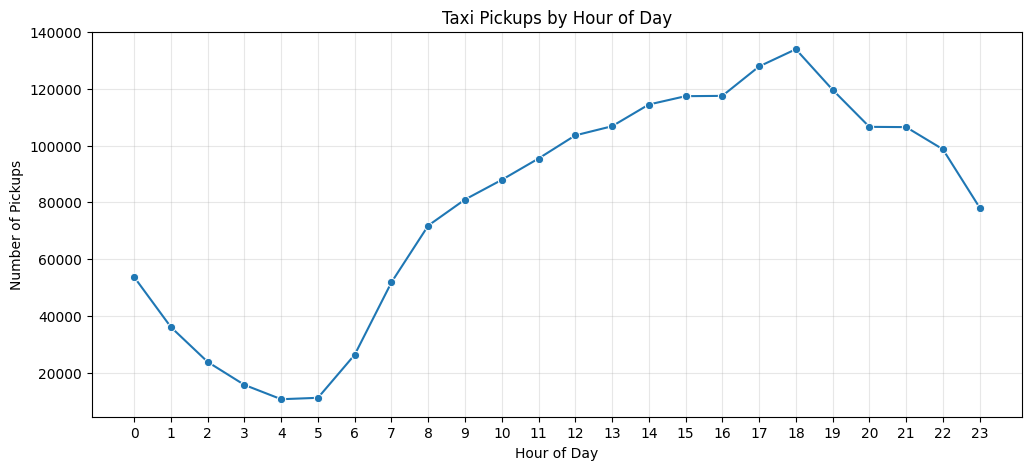

In [106]:
# Find and show the hourly trends in taxi pickups

hourly_pickups = df['tpep_pickup_datetime'].dt.hour.value_counts().sort_index()

plt.figure(figsize=(12, 5))
sns.lineplot(x=hourly_pickups.index, y=hourly_pickups.values, marker='o')

plt.title('Taxi Pickups by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Pickups')
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.show()

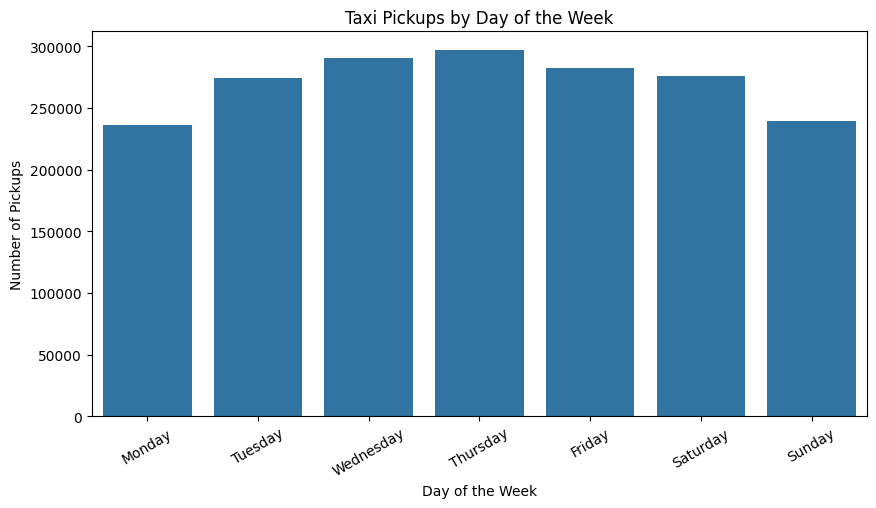

In [107]:
# Find and show the daily trends in taxi pickups (days of the week)

df['pickup_day'] = df['tpep_pickup_datetime'].dt.day_name()

day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

daily_pickups = (
    df['pickup_day']
    .value_counts()
    .reindex(day_order)
)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=daily_pickups.index,
    y=daily_pickups.values
)

plt.title('Taxi Pickups by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Pickups')
plt.xticks(rotation=30)
plt.show()

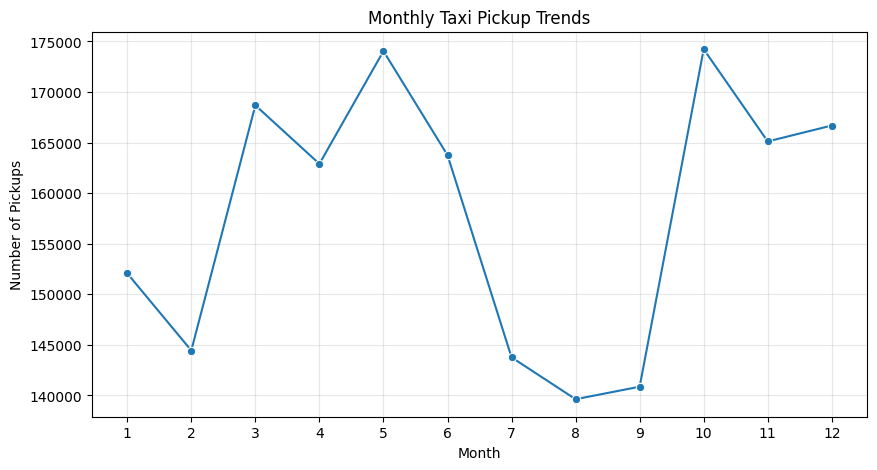

In [108]:
# Show the monthly trends in pickups

df['pickup_month'] = df['tpep_pickup_datetime'].dt.month

monthly_pickups = (
    df['pickup_month']
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 5))
sns.lineplot(
    x=monthly_pickups.index,
    y=monthly_pickups.values,
    marker='o'
)

plt.title('Monthly Taxi Pickup Trends')
plt.xlabel('Month')
plt.ylabel('Number of Pickups')
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.show()

##### Financial Analysis

Take a look at the financial parameters like `fare_amount`, `tip_amount`, `total_amount`, and also `trip_distance`. Do these contain zero/negative values?

In [109]:
# Analyse the above parameters

selected_columns = [
    'fare_amount',
    'tip_amount',
    'total_amount',
    'trip_distance'
]

zero_counts = (df[selected_columns] == 0).sum()
negative_counts = (df[selected_columns] < 0).sum()

print("Zero values:")
print(zero_counts)

print("\nNegative values:")
print(negative_counts)

Zero values:
fare_amount         514
tip_amount       435772
total_amount        264
trip_distance     37608
dtype: int64

Negative values:
fare_amount      0
tip_amount       0
total_amount     0
trip_distance    0
dtype: int64


Do you think it is beneficial to create a copy DataFrame leaving out the zero values from these?

**3.1.3** <font color = red>[2 marks]</font> <br>
Filter out the zero values from the above columns.

**Note:** The distance might be 0 in cases where pickup and drop is in the same zone. Do you think it is suitable to drop such cases of zero distance?

In [110]:
# Create a df with non zero entries for the selected parameters.

df_non_zero = df[
    (df['fare_amount'] > 0) &
    (df['tip_amount'] > 0) &
    (df['total_amount'] > 0) &
    (df['trip_distance'] > 0)
].copy()

print("Original dataset shape:", df.shape)
print("Filtered dataset shape:", df_non_zero.shape)

Original dataset shape: (1896160, 21)
Filtered dataset shape: (1451227, 21)


**3.1.4** <font color = red>[3 marks]</font> <br>
Analyse the monthly revenue (`total_amount`) trend

Monthly Revenue:
pickup_month
1     4159865.02
2     3941710.31
3     4755393.94
4     4677013.15
5     5109369.42
6     4809086.30
7     4176605.87
8     4080255.37
9     4382986.30
10    5179129.33
11    4807606.88
12    4861643.29
Name: total_amount, dtype: float64


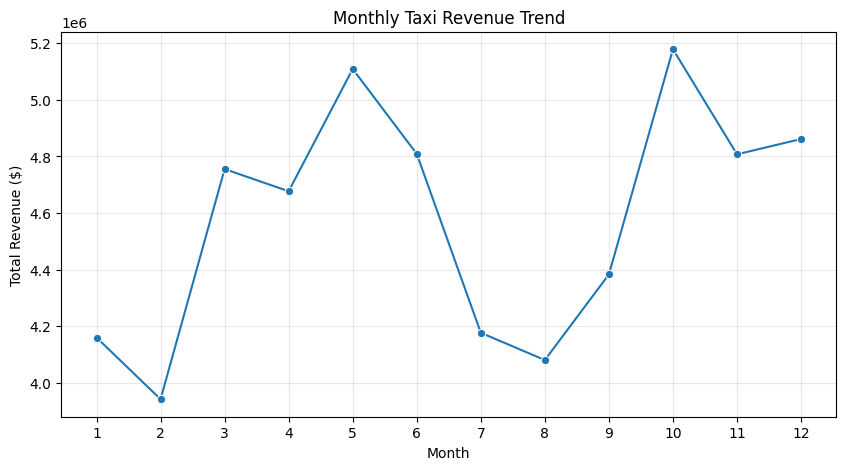

In [111]:
# Group data by month and analyse monthly revenue

df['pickup_month'] = df['tpep_pickup_datetime'].dt.month

monthly_revenue = (
    df.groupby('pickup_month')['total_amount']
      .sum()
      .sort_index()
)

print("Monthly Revenue:")
print(monthly_revenue)

plt.figure(figsize=(10, 5))
sns.lineplot(
    x=monthly_revenue.index,
    y=monthly_revenue.values,
    marker='o'
)

plt.title('Monthly Taxi Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Total Revenue ($)')
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.show()

**3.1.5** <font color = red>[3 marks]</font> <br>
Show the proportion of each quarter of the year in the revenue

Quarterly Revenue:
quarter
1    12856969.27
2    14595468.87
3    12639847.54
4    14848379.50
Name: total_amount, dtype: float64

Proportion of Annual Revenue (%):
quarter
1    23.401554
2    26.565876
3    23.006361
4    27.026210
Name: total_amount, dtype: float64


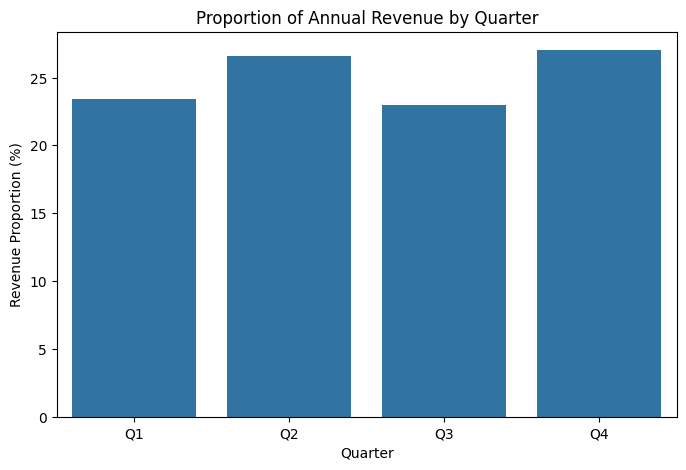

In [112]:
# Calculate proportion of each quarter

df['quarter'] = df['tpep_pickup_datetime'].dt.quarter

quarterly_revenue = (
    df.groupby('quarter')['total_amount']
      .sum()
)

quarterly_revenue_proportion = (
    quarterly_revenue / quarterly_revenue.sum() * 100
)

print("Quarterly Revenue:")
print(quarterly_revenue)

print("\nProportion of Annual Revenue (%):")
print(quarterly_revenue_proportion)

plt.figure(figsize=(8, 5))
sns.barplot(
    x=quarterly_revenue_proportion.index,
    y=quarterly_revenue_proportion.values
)

plt.title('Proportion of Annual Revenue by Quarter')
plt.xlabel('Quarter')
plt.ylabel('Revenue Proportion (%)')
plt.xticks(
    range(4),
    ['Q1', 'Q2', 'Q3', 'Q4']
)
plt.show()

**3.1.6** <font color = red>[3 marks]</font> <br>
Visualise the relationship between `trip_distance` and `fare_amount`. Also find the correlation value for these two.

**Hint:** You can leave out the trips with trip_distance = 0

Correlation between trip distance and fare amount: 0.15773396091573288


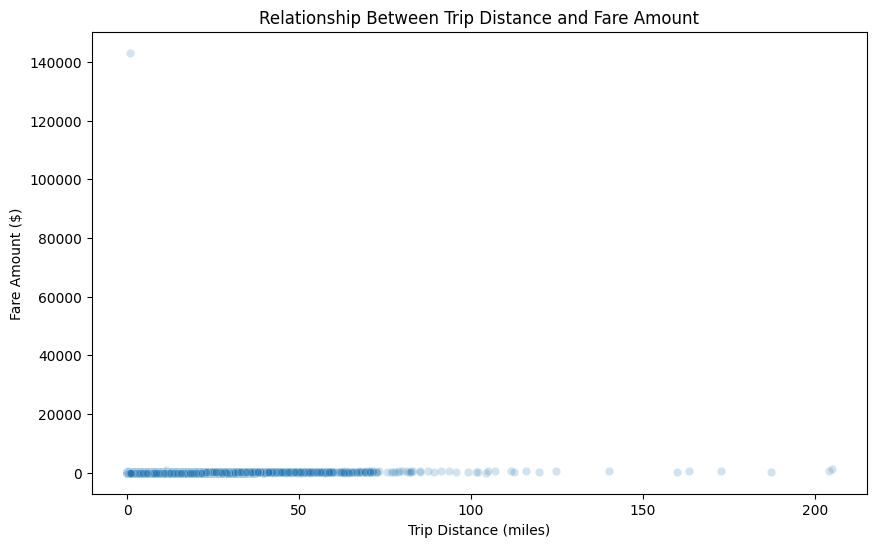

In [113]:
# Show how trip fare is affected by distance

distance_fare = df[
    (df['trip_distance'] > 0) &
    (df['fare_amount'] > 0)
][['trip_distance', 'fare_amount']].copy()

correlation_distance_fare = (
    distance_fare['trip_distance']
    .corr(distance_fare['fare_amount'])
)

print("Correlation between trip distance and fare amount:",
      correlation_distance_fare)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=distance_fare,
    x='trip_distance',
    y='fare_amount',
    alpha=0.2
)

plt.title('Relationship Between Trip Distance and Fare Amount')
plt.xlabel('Trip Distance (miles)')
plt.ylabel('Fare Amount ($)')
plt.show()

**3.1.7** <font color = red>[5 marks]</font> <br>
Find and visualise the correlation between:
1. `fare_amount` and trip duration (pickup time to dropoff time)
2. `fare_amount` and `passenger_count`
3. `tip_amount` and `trip_distance`

Correlation between fare amount and trip duration: 0.0458135033424365


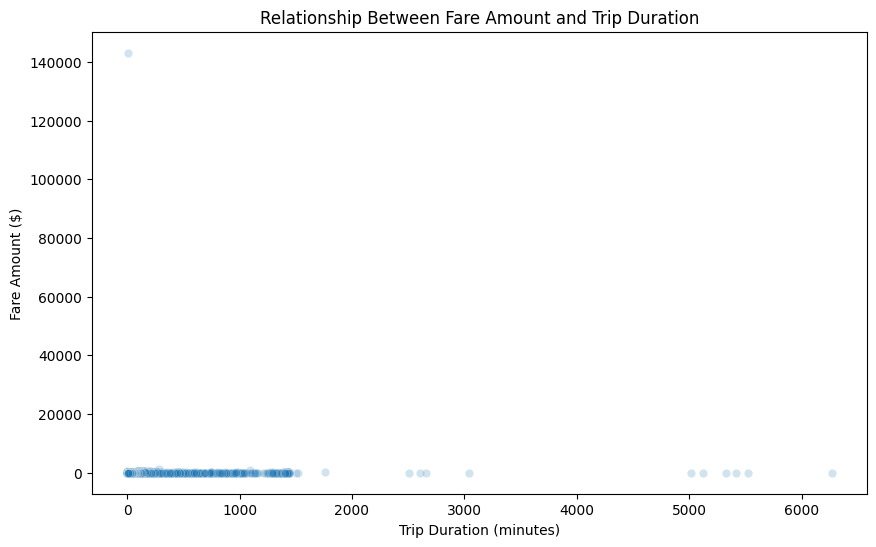

In [114]:
# Show relationship between fare and trip duration

df['trip_duration'] = (
    df['tpep_dropoff_datetime'] -
    df['tpep_pickup_datetime']
).dt.total_seconds() / 60

fare_duration = df[
    (df['trip_duration'] > 0) &
    (df['fare_amount'] > 0)
][['trip_duration', 'fare_amount']].copy()

correlation_fare_duration = (
    fare_duration['fare_amount']
    .corr(fare_duration['trip_duration'])
)

print("Correlation between fare amount and trip duration:",
      correlation_fare_duration)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=fare_duration,
    x='trip_duration',
    y='fare_amount',
    alpha=0.2
)

plt.title('Relationship Between Fare Amount and Trip Duration')
plt.xlabel('Trip Duration (minutes)')
plt.ylabel('Fare Amount ($)')
plt.show()

Correlation between fare amount and passenger count: 0.006809266370449904


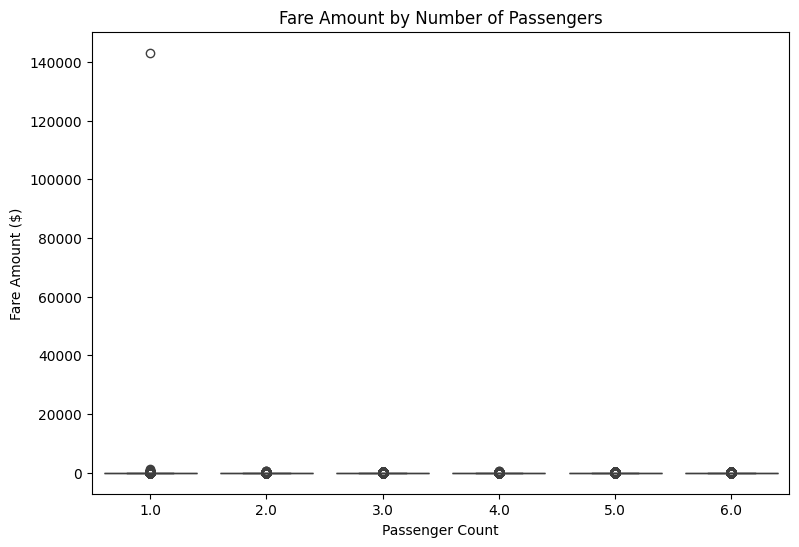

In [115]:
# Show relationship between fare and number of passengers

fare_passengers = df[
    (df['fare_amount'] > 0) &
    (df['passenger_count'] > 0)
][['fare_amount', 'passenger_count']].copy()

correlation_fare_passengers = (
    fare_passengers['fare_amount']
    .corr(fare_passengers['passenger_count'])
)

print("Correlation between fare amount and passenger count:",
      correlation_fare_passengers)

plt.figure(figsize=(9, 6))
sns.boxplot(
    data=fare_passengers,
    x='passenger_count',
    y='fare_amount'
)

plt.title('Fare Amount by Number of Passengers')
plt.xlabel('Passenger Count')
plt.ylabel('Fare Amount ($)')
plt.show()

Correlation between tip amount and trip distance: 0.7969728076151621


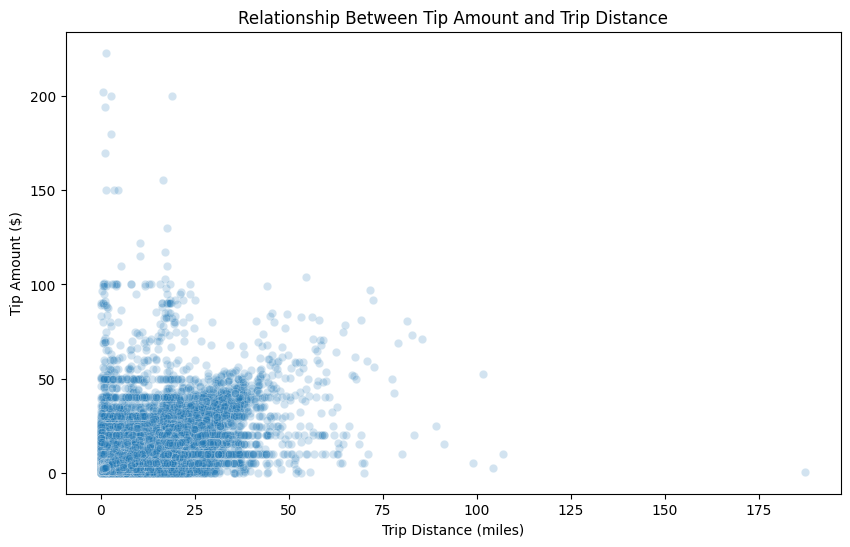

In [116]:
# Show relationship between tip and trip distance

tip_distance = df[
    (df['tip_amount'] > 0) &
    (df['trip_distance'] > 0)
][['tip_amount', 'trip_distance']].copy()

correlation_tip_distance = (
    tip_distance['tip_amount']
    .corr(tip_distance['trip_distance'])
)

print("Correlation between tip amount and trip distance:",
      correlation_tip_distance)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=tip_distance,
    x='trip_distance',
    y='tip_amount',
    alpha=0.2
)

plt.title('Relationship Between Tip Amount and Trip Distance')
plt.xlabel('Trip Distance (miles)')
plt.ylabel('Tip Amount ($)')
plt.show()

**3.1.8** <font color = red>[3 marks]</font> <br>
Analyse the distribution of different payment types (`payment_type`)

Payment Type Distribution:
payment_type
Flex Fare        64844
Credit Card    1492299
Cash            316342
No Charge         9006
Dispute          13669
Name: count, dtype: int64


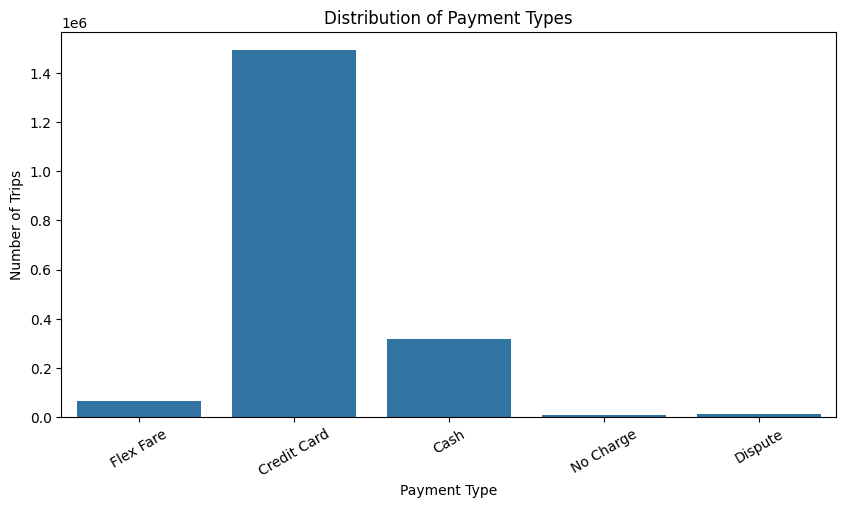

In [117]:
# Analyse the distribution of different payment types (payment_type).

payment_type_counts = df['payment_type'].value_counts().sort_index()

payment_type_labels = {
    0: 'Flex Fare',
    1: 'Credit Card',
    2: 'Cash',
    3: 'No Charge',
    4: 'Dispute',
    5: 'Unknown',
    6: 'Voided Trip'
}

payment_type_distribution = payment_type_counts.rename(
    index=payment_type_labels
)

print("Payment Type Distribution:")
print(payment_type_distribution)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=payment_type_distribution.index,
    y=payment_type_distribution.values
)

plt.title('Distribution of Payment Types')
plt.xlabel('Payment Type')
plt.ylabel('Number of Trips')
plt.xticks(rotation=30)
plt.show()

- 1= Credit card
- 2= Cash
- 3= No charge
- 4= Dispute



##### Geographical Analysis

For this, you have to use the *taxi_zones.shp* file from the *taxi_zones* folder.

There would be multiple files inside the folder (such as *.shx, .sbx, .sbn* etc). You do not need to import/read any of the files other than the shapefile, *taxi_zones.shp*.

Do not change any folder structure - all the files need to be present inside the folder for it to work.

The folder structure should look like this:
```
Taxi Zones
|- taxi_zones.shp.xml
|- taxi_zones.prj
|- taxi_zones.sbn
|- taxi_zones.shp
|- taxi_zones.dbf
|- taxi_zones.shx
|- taxi_zones.sbx

 ```

 You only need to read the `taxi_zones.shp` file. The *shp* file will utilise the other files by itself.

We will use the *GeoPandas* library for geopgraphical analysis
```
import geopandas as gpd
```

More about geopandas and shapefiles: [About](https://geopandas.org/en/stable/about.html)


Reading the shapefile is very similar to *Pandas*. Use `gpd.read_file()` function to load the data (*taxi_zones.shp*) as a GeoDataFrame. Documentation: [Reading and Writing Files](https://geopandas.org/en/stable/docs/user_guide/io.html)

In [99]:
# !pip install geopandas

**3.1.9** <font color = red>[2 marks]</font> <br>
Load the shapefile and display it.

In [100]:
# import geopandas as gpd


# Read the shapefile using geopandas
zones = # read the .shp file using gpd
zones.head()

SyntaxError: invalid syntax (91537633.py, line 5)

Now, if you look at the DataFrame created, you will see columns like: `OBJECTID`,`Shape_Leng`, `Shape_Area`, `zone`, `LocationID`, `borough`, `geometry`.
<br><br>

Now, the `locationID` here is also what we are using to mark pickup and drop zones in the trip records.

The geometric parameters like shape length, shape area and geometry are used to plot the zones on a map.

This can be easily done using the `plot()` method.

In [ ]:
# print(zones.info())
# zones.plot()

Now, you have to merge the trip records and zones data using the location IDs.



**3.1.10** <font color = red>[3 marks]</font> <br>
Merge the zones data into trip data using the `locationID` and `PULocationID` columns.

In [ ]:
# Merge zones and trip records using locationID and PULocationID



**3.1.11** <font color = red>[3 marks]</font> <br>
Group data by location IDs to find the total number of trips per location ID

In [ ]:
# Group data by location and calculate the number of trips



**3.1.12** <font color = red>[2 marks]</font> <br>
Now, use the grouped data to add number of trips to the GeoDataFrame.

We will use this to plot a map of zones showing total trips per zone.

In [ ]:
# Merge trip counts back to the zones GeoDataFrame




The next step is creating a color map (choropleth map) showing zones by the number of trips taken.

Again, you can use the `zones.plot()` method for this. [Plot Method GPD](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.plot.html#geopandas.GeoDataFrame.plot)

But first, you need to define the figure and axis for the plot.

`fig, ax = plt.subplots(1, 1, figsize = (12, 10))`

This function creates a figure (fig) and a single subplot (ax)

---

After setting up the figure and axis, we can proceed to plot the GeoDataFrame on this axis. This is done in the next step where we use the plot method of the GeoDataFrame.

You can define the following parameters in the `zones.plot()` method:
```
column = '',
ax = ax,
legend = True,
legend_kwds = {'label': "label", 'orientation': "<horizontal/vertical>"}
```

To display the plot, use `plt.show()`.

**3.1.13** <font color = red>[3 marks]</font> <br>
Plot a color-coded map showing zone-wise trips

In [ ]:
# Define figure and axis


# Plot the map and display it



In [ ]:
# can you try displaying the zones DF sorted by the number of trips?



Here we have completed the temporal, financial and geographical analysis on the trip records.

**Compile your findings from general analysis below:**

You can consider the following points:

* Busiest hours, days and months
* Trends in revenue collected
* Trends in quarterly revenue
* How fare depends on trip distance, trip duration and passenger counts
* How tip amount depends on trip distance
* Busiest zones


#### **3.2** Detailed EDA: Insights and Strategies
<font color = red>[50 marks]</font> <br>

Having performed basic analyses for finding trends and patterns, we will now move on to some detailed analysis focussed on operational efficiency, pricing strategies, and customer experience.

##### Operational Efficiency

Analyze variations by time of day and location to identify bottlenecks or inefficiencies in routes

**3.2.1** <font color = red>[3 marks]</font> <br>
Identify slow routes by calculating the average time taken by cabs to get from one zone to another at different hours of the day.

Speed on a route *X* for hour *Y* = (*distance of the route X / average trip duration for hour Y*)

In [ ]:
# Find routes which have the slowest speeds at different times of the day



How does identifying high-traffic, high-demand routes help us?

**3.2.2** <font color = red>[3 marks]</font> <br>
Calculate the number of trips at each hour of the day and visualise them. Find the busiest hour and show the number of trips for that hour.

In [ ]:
# Visualise the number of trips per hour and find the busiest hour



Remember, we took a fraction of trips. To find the actual number, you have to scale the number up by the sampling ratio.

**3.2.3** <font color = red>[2 mark]</font> <br>
Find the actual number of trips in the five busiest hours

In [ ]:
# Scale up the number of trips

# Fill in the value of your sampling fraction and use that to scale up the numbers
sample_fraction =



**3.2.4** <font color = red>[3 marks]</font> <br>
Compare hourly traffic pattern on weekdays. Also compare for weekend.

In [ ]:
# Compare traffic trends for the week days and weekends



What can you infer from the above patterns? How will finding busy and quiet hours for each day help us?

**3.2.5** <font color = red>[3 marks]</font> <br>
Identify top 10 zones with high hourly pickups. Do the same for hourly dropoffs. Show pickup and dropoff trends in these zones.

In [ ]:
# Find top 10 pickup and dropoff zones



**3.2.6** <font color = red>[3 marks]</font> <br>
Find the ratio of pickups and dropoffs in each zone. Display the 10 highest (pickup/drop) and 10 lowest (pickup/drop) ratios.

In [ ]:
# Find the top 10 and bottom 10 pickup/dropoff ratios



**3.2.7** <font color = red>[3 marks]</font> <br>
Identify zones with high pickup and dropoff traffic during night hours (11PM to 5AM)

In [ ]:
# During night hours (11pm to 5am) find the top 10 pickup and dropoff zones
# Note that the top zones should be of night hours and not the overall top zones



Now, let us find the revenue share for the night time hours and the day time hours. After this, we will move to deciding a pricing strategy.

**3.2.8** <font color = red>[2 marks]</font> <br>
Find the revenue share for nighttime and daytime hours.

In [ ]:
# Filter for night hours (11 PM to 5 AM)



##### Pricing Strategy

**3.2.9** <font color = red>[2 marks]</font> <br>
For the different passenger counts, find the average fare per mile per passenger.

For instance, suppose the average fare per mile for trips with 3 passengers is 3 USD/mile, then the fare per mile per passenger will be 1 USD/mile.

In [ ]:
# Analyse the fare per mile per passenger for different passenger counts




**3.2.10** <font color = red>[3 marks]</font> <br>
Find the average fare per mile by hours of the day and by days of the week

In [ ]:
# Compare the average fare per mile for different days and for different times of the day



**3.2.11** <font color = red>[3 marks]</font> <br>
Analyse the average fare per mile for the different vendors for different hours of the day

In [ ]:
# Compare fare per mile for different vendors



**3.2.12** <font color = red>[5 marks]</font> <br>
Compare the fare rates of the different vendors in a tiered fashion. Analyse the average fare per mile for distances upto 2 miles. Analyse the fare per mile for distances from 2 to 5 miles. And then for distances more than 5 miles.


In [ ]:
# Defining distance tiers



##### Customer Experience and Other Factors

**3.2.13** <font color = red>[5 marks]</font> <br>
Analyse average tip percentages based on trip distances, passenger counts and time of pickup. What factors lead to low tip percentages?

In [ ]:
#  Analyze tip percentages based on distances, passenger counts and pickup times



Additional analysis [optional]: Let's try comparing cases of low tips with cases of high tips to find out if we find a clear aspect that drives up the tipping behaviours

In [ ]:
# Compare trips with tip percentage < 10% to trips with tip percentage > 25%



**3.2.14** <font color = red>[3 marks]</font> <br>
Analyse the variation of passenger count across hours and days of the week.

In [ ]:
# See how passenger count varies across hours and days




**3.2.15** <font color = red>[2 marks]</font> <br>
Analyse the variation of passenger counts across zones

In [ ]:
# How does passenger count vary across zones



In [ ]:
# For a more detailed analysis, we can use the zones_with_trips GeoDataFrame
# Create a new column for the average passenger count in each zone.



Find out how often surcharges/extra charges are applied to understand their prevalance

**3.2.16** <font color = red>[5 marks]</font> <br>
Analyse the pickup/dropoff zones or times when extra charges are applied more frequently

In [ ]:
# How often is each surcharge applied?



## **4** Conclusion
<font color = red>[15 marks]</font> <br>

### **4.1** Final Insights and Recommendations
<font color = red>[15 marks]</font> <br>

Conclude your analyses here. Include all the outcomes you found based on the analysis.

Based on the insights, frame a concluding story explaining suitable parameters such as location, time of the day, day of the week etc. to be kept in mind while devising a strategy to meet customer demand and optimise supply.

**4.1.1** <font color = red>[5 marks]</font> <br>
Recommendations to optimize routing and dispatching based on demand patterns and operational inefficiencies

**4.1.2** <font color = red>[5 marks]</font> <br>

Suggestions on strategically positioning cabs across different zones to make best use of insights uncovered by analysing trip trends across time, days and months.

**4.1.3** <font color = red>[5 marks]</font> <br>
Propose data-driven adjustments to the pricing strategy to maximize revenue while maintaining competitive rates with other vendors.